# Take-Up Gaps and Administrative Burden — SNAP and the EITC across the States

**Artifact class:** `tutorial`  ·  **Data mode:** `empirical`  ·  **Vintage:** USDA FNS *Reaching Those in Need* (fiscal years 2016, 2017, 2018, 2019 and 2022), FNS *State Options Report* (12th, 14th, 15th and 17th editions) and the IRS EITC participation table (tax years 2014 to 2022)

This notebook uses **real data only**. There is no synthetic generator and no fallback. The state tables exist only inside PDFs, so they are read
from the PDF text by a tested parser (never typed in). The parser is tested on constructed text and on the real extracted text of the tables and profile pages it reads. Each table is checked for coverage and range, and
the restated years and the options report's own summary lists are compared with what was read, as consistency checks that are named as such below.

The analysis was fixed in a written plan (`pap/I01_plan.md`) committed before any retrieval, and three amendments, each committed on its own before the result it concerns was computed. Amendments 1 and 2 were written after the approved
files had been **read for layout on 27 October 2026** (the retrievals are in the run ledger, reconstructed because they left no record). That reading included the parse of the fiscal 2019 table and, before amendment 2, the printed feature values and the restated-year agreement.
Amendment 3 is an owner ruling that made fiscal 2019 the primary year. Every provenance record carries the plan and the amendments in force. The notebook says where it departs from the plan.

**This is association across states. It is not the effect of any administrative feature.**

*Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

By the end of this notebook you will be able to:

1. **Define** a take-up gap as the share of eligible people who do not receive a benefit, and say what the participation rate it comes from does and does not contain.
2. **Read** a state table out of a PDF with a parser whose behaviour is tested on real text, and check the result against the next report that restates it and against the report's own summary.
3. **Estimate** an association between a state's administrative choice and its take-up gap, with an interval from resampling states, and apply a multiple-comparison correction.
4. **Say** why a cross-state association between an administrative feature and take-up does not identify an effect, and name the design that would.

## Prerequisites

**Knowledge.** Rank correlation; a bootstrap that resamples whole units; the idea of a multiple-comparison family.

**Setup.** No key is needed. The notebook downloads nine PDFs from the USDA Food and Nutrition Service (five *Reaching* reports and four *State Options* editions) and one HTML table from the IRS, **once each per run**, and reuses the bytes. Each retrieval is recorded in `provenance/`
with the SHA-256 of what was received, and every fetch, including a failed one, is a line in the run ledger.

**Packages.** `pandas`, `numpy`, `scipy`, `matplotlib`, `pypdf` (see `DECISIONS/0010`) and the local `krl_tutorials_data` package (`pdf_tables`, `uncertainty`).

**Prior notebooks.** C03 shows the staggered-adoption design that this notebook says would be needed to move from association to effect.

## Data Provenance

| Item | Source | Role |
|---|---|---|
| SNAP participation rates, fiscal years 2016, 2017, 2018, 2019, 2022 | USDA FNS, *Reaching Those in Need*, the report for each year | the take-up gap (100 minus the rate) |
| Online application; certification length | USDA FNS, *State Options Report*, 12th edition (options as of 1 October 2015) and 14th edition (as of 1 October 2017), each state's profile page; the 15th and 17th editions are searched for the same features | the two administrative features |
| EITC participation rate by state | IRS, *EITC participation rate by state*, the table on the page | a second take-up gap |
| `data/policy/medicaid/expansion_dates.csv` | repository policy table | the list of 51 jurisdictions (50 states and the District of Columbia). The plan names the repository's FIPS table for this list; this file was used instead and has the same 51 names |

> **What a participation rate is.** FNS defines it as the number of people participating divided by the number eligible, estimated from survey and administrative data.
> The state rates are **model estimates**, not direct counts: each report states that it uses a shrinkage estimator that averages direct sample estimates with predictions from a regression model (the sentences are printed in Part 1). The later reports cap the rate at 100.
> The reports show 90 percent confidence intervals only in a chart whose text cannot be read in order (Part 1 shows why), so no interval is carried and every gap below is a point estimate.

## Design

**Estimands, all descriptive.**

1. The SNAP take-up gap by state: `100 - participation rate`, in percentage points of eligible people who did not receive SNAP.
2. Its association with two features read from the same state's profile in the options report: whether the state offered an **online application**, and its **certification length**
   (the longest period it uses, in months).
3. The EITC take-up gap and its rank correlation with the SNAP gap.

**Which year is primary, and how that was decided.** Plan section 4 joins each fiscal year to the options edition nearest its start, within eighteen months, and makes the **latest fiscal year with a pairing the primary year**. Fiscal 2019 begins on 1 October 2018 and the 14th edition's options are as of 1 October 2017, twelve months earlier,
so **fiscal 2019 with the 14th edition is the primary year**. Amendment 1, written on 27 October, named fiscal 2018 instead; that misapplied the rule, and the fiscal 2019 table had already been parsed in the layout read that preceded it (it gave fewer than 51 jurisdictions because of split names, which the amendment repairs). No gap or association had been computed for any year.
The owner ruled on 29 October 2026 to follow the plan (amendment 3, committed before this notebook was re-run). **Fiscal 2018 (14th edition) and fiscal 2016 (12th edition) are replications**, not pooled and not corrected.

**Why the options test stops there.** Part 2 reads the "as of" dates of all four editions and prints the pairing for every fiscal year, then searches the editions near fiscal 2022 for the two features with several terms, and prints what it finds and what that means for the test.

**Rules fixed before the data.** The two feature tests in the primary year are one family, corrected by Holm at the level in the configuration cell. The expected direction was written down first:
online application and longer certification go with a **smaller** gap; the SNAP and EITC gaps are **positively** correlated. A null is stated with its interval, never as "no association". Anything added after review is labelled in the cell where it appears and in Limitations.

In [1]:
"""Configuration. Every analytic choice is named here, not inferred."""
from __future__ import annotations

import hashlib
import io
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pypdf
from pypdf import PdfReader
from scipy import stats

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src"))
        REPO_ROOT = _cand
        break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data import pdf_tables, provenance
from krl_tutorials_data.methods import resample
from krl_tutorials_data.sources import fetch_fns_pdf, fetch_irs_eitc_participation
from krl_tutorials_data.uncertainty import holm_bonferroni

NB_DIR = REPO_ROOT / "projects" / "14-implementation" / "I01_benefit_take_up_administrative_burden"
PLAN = NB_DIR / "pap" / "I01_plan.md"
AMEND = [NB_DIR / "pap" / f"I01_plan_amendment_{k}.md" for k in (1, 2, 3)]
PLAN_SHA256 = hashlib.sha256(PLAN.read_bytes()).hexdigest()
provenance.use_ledger(NB_DIR / "provenance" / "_runs.jsonl", PLAN, *AMEND)   # every fetch below appends to the run ledger, before it raises as well as after it succeeds


def stop(message: str) -> None:
    """Append a stopped line to the run ledger, then raise."""
    provenance.ledger_stop(message)
    raise SystemExit(message)


REPORTS = {2016: "resource-files/Reaching2016.pdf", 2017: "resource-files/Reaching2017-1.pdf",
           2018: "resource-files/Reaching2018.pdf", 2019: "resource-files/snap2019reaching.pdf",
           2022: "resource-files/ear-snap-Reaching-Those-in-Need-2022.pdf"}
EDITION_FILES = {"12th": "snap/12-State_Options.pdf", "14th": "snap/14-State-Options.pdf",
                 "15th": "resource-files/snap-15th-state-options-report-october23.pdf",
                 "17th": "resource-files/snap-stateOptionsReport-17edition-120925.pdf"}
USED = {2019: "14th", 2018: "14th", 2016: "12th"}        # amendment 3: primary first, then the two replications
PRIMARY, REPLICATIONS, LATEST = 2019, (2018, 2016), 2022
ASSOC_YEARS = (PRIMARY, *REPLICATIONS)
ALPHA, N_BOOT, SEED, MAX_MONTHS_APART, MAX_EXCLUDED_DESCRIPTIVE = 0.05, 9999, 20261027, 18, 3
REVISION_FLAG = 5          # points; restated values that differ from the original report's by more than this are listed
ADDED = "not pre-specified (added after review, 2026-10-29)"

jur = pd.read_csv(REPO_ROOT / "data" / "policy" / "medicaid" / "expansion_dates.csv")["state"].tolist()
if len(jur) != 51 or len(set(jur)) != 51:
    stop("expected 51 distinct jurisdictions")
ALIASES = {"DC": "District of Columbia"}

PLAN_HISTORY = [  # file, author time (UTC) of the commit that first held it, relation to the first retrieval; the same times are in krl.pap, which the plan-binding gate checks against git history
    ("I01_plan.md", "2026-10-27 20:53:39Z", "before"),
    ("I01_plan_amendment_1.md", "2026-10-27 21:13:02Z", "after"),
    ("I01_plan_amendment_2.md", "2026-10-27 22:30:42Z", "after"),
    ("I01_plan_amendment_3.md", "2026-10-29 03:55:00Z", "after"),
]
print("plan and amendments (first approved file retrieved, for layout, at 2026-10-27 21:02:24Z)")
for (name_, when_, rel_), path_ in zip(PLAN_HISTORY, [PLAN, *AMEND]):
    print(f"  {name_:26s} author time {when_}  {rel_} that retrieval  SHA-256 {hashlib.sha256(path_.read_bytes()).hexdigest()[:12]}")
print(f"plan SHA-256         : {PLAN_SHA256}")
print(f"jurisdictions        : {len(jur)}")
print(f"primary / replications: fiscal {PRIMARY} / fiscal {REPLICATIONS[0]} and fiscal {REPLICATIONS[1]}; descriptive only: fiscal {LATEST}")
print(f"alpha {ALPHA}; bootstrap {N_BOOT:,} draws, seed {SEED}; pairing limit {MAX_MONTHS_APART} months")
print(f"pypdf {pypdf.__version__}")
print(f"files retrieved, once each per run: {len(REPORTS)} Reaching reports, {len(EDITION_FILES)} options editions, 1 IRS table")

plan and amendments (first approved file retrieved, for layout, at 2026-10-27 21:02:24Z)
  I01_plan.md                author time 2026-10-27 20:53:39Z  before that retrieval  SHA-256 07683027fa91
  I01_plan_amendment_1.md    author time 2026-10-27 21:13:02Z  after that retrieval  SHA-256 558aa55fe126
  I01_plan_amendment_2.md    author time 2026-10-27 22:30:42Z  after that retrieval  SHA-256 bf50dc548aa1
  I01_plan_amendment_3.md    author time 2026-10-29 03:55:00Z  after that retrieval  SHA-256 f55611d73914
plan SHA-256         : 07683027fa91f5525be1fe979fa71252f9d828fd9fd33176833d51b88798d206
jurisdictions        : 51
primary / replications: fiscal 2019 / fiscal 2018 and fiscal 2016; descriptive only: fiscal 2022
alpha 0.05; bootstrap 9,999 draws, seed 20261027; pairing limit 18 months
pypdf 6.0.0
files retrieved, once each per run: 5 Reaching reports, 4 options editions, 1 IRS table


## Part 1 · Reading the rates out of the PDFs

Each report is downloaded once and recorded; the bytes are kept and reused by every later cell. The page holding the table is found by its heading; every row must name one of the 51 jurisdictions. Three
repairs, all stated in the amendment and all printed when they happen: a name split across lines, a number split in two, and nothing else. A row that
cannot be read is excluded and named with its raw line, its value count and the reason, never filled.

In [2]:
"""Download the five reports once and read each state table twice."""
BODY = {}


def table_page(pages, fy):
    """The page carrying the heading 'Estimates of participation rates' and the most jurisdiction rows.

    The heading phrase also occurs in running text on other pages, so the pages that carry it are ranked
    by how many distinct jurisdictions they have as rows; a page needs at least 40, and the best must stand alone.
    """
    hits = pdf_tables.find_pages(pages, "Estimates of participation rates")
    score = {}
    for i in hits:
        lines, _ = pdf_tables.repair_split_names(pages[i].splitlines(), jur)
        score[i] = len({r.name for r in pdf_tables.parse_jurisdiction_rows(lines, jur).rows})
    ranked = sorted(score.items(), key=lambda kv: -kv[1])
    if not ranked or ranked[0][1] < 40 or (len(ranked) > 1 and ranked[1][1] >= 40):
        stop(f"fiscal {fy}: no single table page; heading pages and their row counts {score}")
    return ranked[0][0]


def years_header(lines, fy, k):
    """The printed column years; the report's own year must be the last of the first k."""
    for line in lines:
        years = [int(y) for y in re.findall(r"\b(20\d\d)\b", line)]
        if len(years) >= k and all(2000 <= y <= 2030 for y in years) and re.fullmatch(r"[\sA-Za-z0-9]*", line):
            if years[k - 1] != fy:
                stop(f"fiscal {fy}: header {line!r} does not end the first {k} columns in {fy}")
            return years[:k], line.strip()
    stop(f"fiscal {fy}: no column-year header found")


def read_rates(body: bytes, fy: int):
    """Return (series, log) for one report: the rate for the report's own fiscal year by jurisdiction."""
    k = 3 if fy <= 2019 else 2
    pages = [p.extract_text() or "" for p in PdfReader(io.BytesIO(body)).pages]
    page = table_page(pages, fy)
    lines = pages[page].splitlines()
    lines, joins = pdf_tables.repair_split_names(lines, jur)
    start = next(i for i, l in enumerate(lines) if "Estimates of participation rates" in l)
    years, header = years_header(lines[start:start + 6], fy, k)
    parsed = pdf_tables.parse_jurisdiction_rows(lines[start:], jur)
    counts = pd.Series([len(r.values) for r in parsed.rows]).value_counts()
    modal = int(counts.idxmax())
    values, cols, merges, excluded = {}, {}, [], []
    for r in parsed.rows:
        got = pdf_tables.reconcile_row(r, expected=modal, max_value=100.0)
        if got is None:
            raw = lines[start + r.line_no - 1].strip()
            why = (f"{len(r.values)} values where the table's usual count is {modal}; "
                   + ("one value too many, but no single merge of an adjacent pair from the fourth value on gives the usual count with every value at most 100"
                      if len(r.values) == modal + 1 else "the count is not one more than usual, so no merge is tried"))
            excluded.append((r.name, raw, len(r.values), why))
            continue
        if len(r.values) != modal:
            merges.append((r.name, r.values, got))
        if r.name in values:
            stop(f"fiscal {fy}: {r.name} appears twice")
        values[r.name] = got[k - 1]
        cols[r.name] = got[:k]
    # the same table read from the whole document's text must agree with the page-by-page read
    whole = "\n".join(pages).splitlines()
    whole, _ = pdf_tables.repair_split_names(whole, jur)
    again = {}
    for r in pdf_tables.parse_jurisdiction_rows(whole, jur).rows:
        got = pdf_tables.reconcile_row(r, expected=modal, max_value=100.0)
        if got is not None and r.name in values and r.name not in again:
            again[r.name] = got[k - 1]
    agree = all(again.get(n) == v for n, v in values.items())
    return pd.Series(values, name=f"rate_{fy}"), {
        "page": page, "header": header, "years": years, "modal": modal, "joins": joins, "merges": merges,
        "excluded": excluded, "rejected": parsed.rejected, "reread_agrees": agree, "cols": cols, "pages": pages}


rates, logs = {}, {}
for fy, path in REPORTS.items():
    body, prov = fetch_fns_pdf(path=path, vintage=f"fiscal year {fy}")
    BODY[path] = body
    prov.with_pap_chain(PLAN, *AMEND).write(NB_DIR / "provenance" / f"i01_fns_reaching_{fy}.json")
    rates[fy], logs[fy] = read_rates(body, fy)
    lg = logs[fy]
    print(f"fiscal {fy}: {len(body):,} bytes, digest {prov.content_sha256[:12]}; table on page {lg['page'] + 1}; header '{lg['header']}'")
    for note in prov.notes:
        if note.startswith(("Last-Modified", "No Last-Modified", "PDF ", "No PDF")):
            print(f"   publisher: {note}")
    print(f"   rows read {len(rates[fy])} of {len(jur)}; name joins {len(lg['joins'])}; number merges {len(lg['merges'])}; excluded {len(lg['excluded'])}; unparsed lines after a name {len(lg['rejected'])}")
    for j in lg["joins"]:
        print(f"   joined {j[1]!r} + {j[2]!r}")
    for name, before, after in lg["merges"]:
        print(f"   merged in {name}: {tuple(int(v) for v in before)} -> {tuple(int(v) for v in after)}")
    for name, raw, nvals, why in lg["excluded"]:
        print(f"   EXCLUDED {name}: raw line {raw!r}; {nvals} value(s); {why}")
    for rj in lg["rejected"]:
        print(f"   unparsed line {rj.line_no}: {rj.line!r}; {rj.reason}")
    print(f"   whole-document read gives the same table as the page-by-page read: {lg['reread_agrees']} (a consistency check on the extraction, not a validation of it: both reads use the same parser on the same text)")

fiscal 2016: 647,644 bytes, digest de54239d9c1a; table on page 5; header '2014      2015    2016 2014         2015 2016'
   publisher: Last-Modified: Mon, 05 Oct 2020 15:52:07 GMT; ETag: "9e1dc-5b0ee76eaaba9".
   publisher: PDF CreationDate D:20190227135848-05'00'; PDF ModDate D:20190301121300-05'00'.
   rows read 51 of 51; name joins 0; number merges 0; excluded 0; unparsed lines after a name 0
   whole-document read gives the same table as the page-by-page read: True (a consistency check on the extraction, not a validation of it: both reads use the same parser on the same text)


fiscal 2017: 1,134,902 bytes, digest c03ce0190e78; table on page 5; header '2015      2016    2017 2015         2016 2017'
   publisher: Last-Modified: Mon, 05 Oct 2020 15:55:19 GMT; ETag: "115136-5b0ee82628d8c".
   publisher: PDF CreationDate D:20200908184030-04'00'; PDF ModDate D:20200909122355-04'00'.
   rows read 51 of 51; name joins 0; number merges 0; excluded 0; unparsed lines after a name 0
   whole-document read gives the same table as the page-by-page read: True (a consistency check on the extraction, not a validation of it: both reads use the same parser on the same text)


fiscal 2018: 1,428,103 bytes, digest b7b8f5e89898; table on page 5; header '2016      2017    2018 2016         2017 2018'
   publisher: Last-Modified: Wed, 19 May 2021 13:11:06 GMT; ETag: "15ca87-5c2ae8f3bb59e".
   publisher: No PDF CreationDate or ModDate was found in the file.
   rows read 51 of 51; name joins 2; number merges 1; excluded 0; unparsed lines after a name 0
   joined 'L' + 'ouisiana 82 86 83 74 74 73'
   joined 'O' + 'regon 100 100 100 91 96 88'
   merged in Oklahoma: (80, 83, 85, 71, 7, 6, 78) -> (80, 83, 85, 71, 76, 78)
   whole-document read gives the same table as the page-by-page read: True (a consistency check on the extraction, not a validation of it: both reads use the same parser on the same text)


fiscal 2019: 980,952 bytes, digest fba23efaf4fa; table on page 5; header '2017 2018 2019 2017 2018 2019'
   publisher: Last-Modified: Mon, 13 Feb 2023 15:25:10 GMT; ETag: "ef7d8-5f49673e422ad".
   publisher: PDF CreationDate D:20221109121504-08'00'; PDF ModDate D:20221109121518-08'00'.
   rows read 51 of 51; name joins 2; number merges 0; excluded 0; unparsed lines after a name 0
   joined 'L' + 'ouisiana 86 84 85 75 73 77'
   joined 'Or' + 'egon 100 100 100 97 90 89'
   whole-document read gives the same table as the page-by-page read: True (a consistency check on the extraction, not a validation of it: both reads use the same parser on the same text)


fiscal 2022: 900,600 bytes, digest 2aec9d73abbd; table on page 4; header 'State 2020 2022'
   publisher: Last-Modified: Mon, 10 Feb 2025 19:57:11 GMT; ETag: "dbdf8-62dcf1d37c8f2".
   publisher: No PDF CreationDate or ModDate was found in the file.
   rows read 50 of 51; name joins 0; number merges 0; excluded 1; unparsed lines after a name 0
   EXCLUDED California: raw line 'California 67'; 1 value(s); 1 values where the table's usual count is 2; the count is not one more than usual, so no merge is tried
   whole-document read gives the same table as the page-by-page read: True (a consistency check on the extraction, not a validation of it: both reads use the same parser on the same text)


In [3]:
"""Coverage rule from the plan and amendments: 51 of 51 for the association years; up to the stated number excluded for the descriptive year."""
cov_ok = True
for fy in ASSOC_YEARS:
    missing = [n for n in jur if n not in rates[fy].index]
    ok = not missing
    cov_ok &= ok
    print(f"FALSIFICATION: coverage_{fy} statistic={len(rates[fy])} of {len(jur)} jurisdictions read; missing {missing or 'none'} verdict={'PASS' if ok else 'FAIL'}")
miss22 = [n for n in jur if n not in rates[LATEST].index]
ok22 = len(miss22) <= MAX_EXCLUDED_DESCRIPTIVE
print(f"FALSIFICATION: coverage_{LATEST} statistic={len(rates[LATEST])} of {len(jur)} jurisdictions read; excluded {miss22 or 'none'}; at most {MAX_EXCLUDED_DESCRIPTIVE} allowed for a descriptive year verdict={'PASS' if ok22 else 'FAIL'}")
rng_ok = all(((r >= 0) & (r <= 100)).all() for r in rates.values())
n100 = {fy: int((r == 100).sum()) for fy, r in rates.items()}
print(f"FALSIFICATION: range statistic={max(r.max() for r in rates.values()):.0f} largest rate read; every rate between 0 and 100 verdict={'PASS' if rng_ok else 'FAIL'}")
print("states at the cap of 100 percent: " + ", ".join(f"fiscal {fy}: {n}" for fy, n in n100.items()))
reread = all(lg["reread_agrees"] for lg in logs.values())
print(f"FALSIFICATION: reread statistic={int(reread)} the whole-document read gives the same table as the page-by-page read in every report (a consistency check) verdict={'PASS' if reread else 'FAIL'}")
if not (cov_ok and ok22 and rng_ok and reread):
    stop("a coverage, range or re-read rule failed; ask the owner")

FALSIFICATION: coverage_2019 statistic=51 of 51 jurisdictions read; missing none verdict=PASS
FALSIFICATION: coverage_2018 statistic=51 of 51 jurisdictions read; missing none verdict=PASS
FALSIFICATION: coverage_2016 statistic=51 of 51 jurisdictions read; missing none verdict=PASS
FALSIFICATION: coverage_2022 statistic=50 of 51 jurisdictions read; excluded ['California']; at most 3 allowed for a descriptive year verdict=PASS
FALSIFICATION: range statistic=100 largest rate read; every rate between 0 and 100 verdict=PASS
states at the cap of 100 percent: fiscal 2016: 7, fiscal 2017: 6, fiscal 2018: 3, fiscal 2019: 10, fiscal 2022: 11
FALSIFICATION: reread statistic=1 the whole-document read gives the same table as the page-by-page read in every report (a consistency check) verdict=PASS


### Estimates are models, and the intervals are not carried

Plan section 3 says to carry an interval if the reports print one. The cell below prints what two of the reports say about how the state rates are made and about their intervals, and what the text layer of the chart that holds the intervals looks like.

In [4]:
"""What the reports say about the estimation method and the intervals (printed from the PDFs)."""
def sentence_with(text, pattern):
    t = " ".join(text.split())
    m = re.search(pattern, t)
    if not m:
        return None
    s = t.rfind(". ", 0, m.start()) + 2
    e = t.find(". ", m.end()) + 1
    return t[max(s, 0):e if e > 0 else None]

for fy in (PRIMARY, 2018):
    text = "\n".join(logs[fy]["pages"])
    print(f"fiscal {fy} report:")
    print("   method  :", sentence_with(text, r"The shrinkage estimator averaged"))
    print("   intervals:", sentence_with(text, r"Each interval displayed here is a (\d+) percent confidence interval"))
    t = " ".join(text.split())
    i = t.find("Participation rates and confidence intervals")
    print("   chart text layer (first 260 characters after the chart title):", t[i + 46:i + 306] if i >= 0 else "chart title not found")
print("The state rates are therefore model-based shrinkage estimates, and the intervals the reports publish are 90 percent intervals in a chart whose text comes out of reading order, so no interval can be attached to a state without matching numbers to states by position. None is carried; every gap below is a point estimate.")

fiscal 2019 report:
   method  : The shrinkage estimator averaged direct sample estimates of participation rates with predictions from a regression model, using data for all the States, all three years, and both groups (all eligible people and working poor people) to derive each estimate.
   intervals: Each interval displayed here is a 90 percent confidence interval.
   chart text layer (first 260 characters after the chart title): percentage) (Estimated participation rates are in red; estimated bounds of confidence intervals are in black.) An asterisk (*) indicates that the State’s participation rate was significantly different from the national rate 77 Eligible People (Thousands) 81 82
fiscal 2018 report:
   method  : The shrinkage estimator averaged direct sample estimates of participation rates with predictions from a regression model, using data for all the States, all three years, and both groups (all eligible people and working poor people) to derive each estimate.
   intervals:

### Consistency check against the later reports' restatements — not pre-specified (added after review, 2026-10-29)

Each later report restates the two earlier years it covers, with the method updated. The comparison below is for every earlier year that the fiscal 2018 and fiscal 2019 reports restate, against the report for that year. It is a consistency check, not a validation: if the parser were reading the wrong column the restated and original values would not resemble each other, but it cannot say the right column was read. States whose restated value differs from the original by more than the flag in the configuration cell are listed. The size of these revisions matters later, because they are the same order as the contrasts being tested.

In [5]:
"""Every restated year in the fiscal 2018 and fiscal 2019 reports against the report for that year."""
print(f"{ADDED}")
revisions = []
for rep, yr in ((2018, 2016), (2018, 2017), (2019, 2017), (2019, 2018)):
    kcol = logs[rep]["years"].index(yr)
    restated = pd.Series({n: v[kcol] for n, v in logs[rep]["cols"].items()}, name="restated")
    both = pd.concat([rates[yr].rename("own"), restated], axis=1, join="inner")
    d = both["restated"] - both["own"]
    revisions.append(d.abs())
    c = both.corr().iloc[0, 1]
    print(f"fiscal {yr} as printed in the fiscal {rep} report vs the fiscal {yr} report, {len(both)} states: mean difference {d.mean():+.1f} points, mean absolute {d.abs().mean():.1f}, largest {d.abs().max():.0f}; correlation {c:.3f}")
    big = d[d.abs() > REVISION_FLAG].sort_values()
    print(f"   differing by more than {REVISION_FLAG} points ({len(big)}): " + (", ".join(f"{n} {both.loc[n, 'own']:.0f}->{both.loc[n, 'restated']:.0f}" for n in big.index) or "none"))
    print(f"CONSISTENCY CHECK: restated_{yr}_in_{rep} statistic={c:.3f} correlation of the two printings of the same year; a column read wrongly would not exceed 0.8 verdict={'PASS' if c > 0.8 else 'FAIL'}")
pooled = pd.concat(revisions)
REVISION_MEAN_ABS = float(pooled.mean())
print(f"all four comparisons together ({len(pooled)} state-years): mean absolute revision {REVISION_MEAN_ABS:.1f} points, largest {pooled.max():.0f}")

not pre-specified (added after review, 2026-10-29)
fiscal 2016 as printed in the fiscal 2018 report vs the fiscal 2016 report, 51 states: mean difference -2.5 points, mean absolute 3.3, largest 11; correlation 0.936
   differing by more than 5 points (11): Montana 87->76, South Dakota 83->72, Vermont 100->90, Michigan 100->91, West Virginia 95->87, Idaho 84->77, Minnesota 84->77, Mississippi 83->76, New Mexico 100->93, Kansas 77->71, Nevada 83->89
CONSISTENCY CHECK: restated_2016_in_2018 statistic=0.936 correlation of the two printings of the same year; a column read wrongly would not exceed 0.8 verdict=PASS
fiscal 2017 as printed in the fiscal 2018 report vs the fiscal 2017 report, 51 states: mean difference -2.5 points, mean absolute 3.0, largest 13; correlation 0.959
   differing by more than 5 points (7): Maine 97->84, Montana 90->81, West Virginia 92->85, District of Columbia 96->90, Minnesota 81->75, South Dakota 82->76, Vermont 100->94
CONSISTENCY CHECK: restated_2017_in_2018 st

## Part 2 · The options editions and the administrative features

The "as of" date of each edition is read from its first pages, the distance to the start of each fiscal year is computed, and every pairing is printed, as plan section 4 requires. The four editions are downloaded once each.

In [6]:
"""Download the four editions, read their 'as of' dates, and print the pairing for every fiscal year."""
EPAGES, ASOF = {}, {}
MONTHS = {m: i + 1 for i, m in enumerate(["january", "february", "march", "april", "may", "june", "july", "august", "september", "october", "november", "december"])}
for ed, path in EDITION_FILES.items():
    body, prov = fetch_fns_pdf(path=path, vintage=f"State Options Report, {ed} edition")
    BODY[path] = body
    prov.with_pap_chain(PLAN, *AMEND).write(NB_DIR / "provenance" / f"i01_fns_options_{ed}.json")
    EPAGES[ed] = [p.extract_text() or "" for p in PdfReader(io.BytesIO(body)).pages]
    head = " ".join(" ".join(EPAGES[ed][:8]).split())
    found = [(m.group(0), MONTHS[m.group(1).lower()], int(m.group(2)), int(m.group(3)))
             for m in re.finditer(r"as\s*of\s*([A-Za-z]+)\s*(\d{1,2}),\s*(\d{4})", head, re.I) if m.group(1).lower() in MONTHS]
    if not found:
        stop(f"{ed} edition: no 'as of' date in the first pages")
    ASOF[ed] = found[0]
    print(f"{ed} edition ({len(EPAGES[ed])} pages, digest {prov.content_sha256[:12]}): 'as of' matches in the first pages {[f[0] for f in found]}; the first is used: {found[0][1]}/{found[0][3]}")
    for note in prov.notes:
        if note.startswith(("Last-Modified", "No Last-Modified", "PDF ", "No PDF")):
            print(f"   publisher: {note}")


def months_between(a, b):
    return abs((a[0] * 12 + a[1]) - (b[0] * 12 + b[1]))


print("\npairing by distance (plan section 4): each fiscal year starts on 1 October of the year before")
PAIR = {}
for fy in (2016, 2017, 2018, 2019, 2022):
    dist = {ed: months_between((fy - 1, 10), (ASOF[ed][3], ASOF[ed][1])) for ed in ASOF}
    best = min(dist.values())
    nearest = [ed for ed, d in dist.items() if d == best]
    ok = best <= MAX_MONTHS_APART and len(nearest) == 1
    PAIR[fy] = nearest[0] if ok else None
    print(f"fiscal {fy}: nearest {'/'.join(nearest)} edition at {best} months" + (" (tie)" if len(nearest) > 1 else "") + ("" if best <= MAX_MONTHS_APART else f"; beyond {MAX_MONTHS_APART} months, no pairing") + f"; all distances {dist}")
for fy, ed in USED.items():
    if PAIR[fy] != ed:
        stop(f"fiscal {fy}: the plan's rule pairs it with {PAIR[fy]}, not the {ed} edition amendment 3 names")
print(f"\nthe pairings for fiscal {PRIMARY}, {REPLICATIONS[0]} and {REPLICATIONS[1]} agree with amendment 3. Fiscal 2017 is equidistant from two editions and no ruling names it, so it is not used for the options test.")

12th edition (82 pages, digest 3fe71ad37b86): 'as of' matches in the first pages ['as of October 1, 2015', 'as of October 1, 2015']; the first is used: 10/2015
   publisher: Last-Modified: Mon, 05 Oct 2020 15:57:35 GMT; ETag: "55a92a-5b0ee8a812a76".
   publisher: No PDF CreationDate or ModDate was found in the file.


14th edition (93 pages, digest 31dc7ac21741): 'as of' matches in the first pages ['as of October 1, 2017', 'as of October 1, 2017']; the first is used: 10/2017
   publisher: Last-Modified: Mon, 05 Oct 2020 15:57:36 GMT; ETag: "68f85b-5b0ee8a8894e2".
   publisher: No PDF CreationDate or ModDate was found in the file.


15th edition (82 pages, digest 1202fcbc8d71): 'as of' matches in the first pages ['as of October 1, 2022', 'as of July 1, 2023']; the first is used: 10/2022
   publisher: Last-Modified: Thu, 11 Jan 2024 15:58:22 GMT; ETag: "1dc658-60ead9df52067".
   publisher: No PDF CreationDate or ModDate was found in the file.


17th edition (149 pages, digest c27018fd44ed): 'as of' matches in the first pages ['as of October 1, 2024']; the first is used: 10/2024
   publisher: Last-Modified: Tue, 09 Dec 2025 18:27:44 GMT; ETag: "599bbd-64589115b8f5c".
   publisher: No PDF CreationDate or ModDate was found in the file.

pairing by distance (plan section 4): each fiscal year starts on 1 October of the year before
fiscal 2016: nearest 12th edition at 0 months; all distances {'12th': 0, '14th': 24, '15th': 84, '17th': 108}
fiscal 2017: nearest 12th/14th edition at 12 months (tie); all distances {'12th': 12, '14th': 12, '15th': 72, '17th': 96}
fiscal 2018: nearest 14th edition at 0 months; all distances {'12th': 24, '14th': 0, '15th': 60, '17th': 84}
fiscal 2019: nearest 14th edition at 12 months; all distances {'12th': 36, '14th': 12, '15th': 48, '17th': 72}
fiscal 2022: nearest 15th edition at 12 months; all distances {'12th': 72, '14th': 48, '15th': 12, '17th': 36}

the pairings for fiscal 2019, 2018 and 2016 agr

In [7]:
"""Read the 12th and 14th editions' state profiles."""
LABELS = {"online": r"Online\s+Application", "length": r"Certification\s+Length"}
feat, PROFS = {}, {}
for ed in ("12th", "14th"):
    pages = EPAGES[ed]
    profs, assigned = pdf_tables.parse_profiles_with_contents(pages, jur, LABELS, ALIASES)
    PROFS[ed] = profs
    for a in assigned:
        print(f"   assigned by page number (amendment 2): {a.name} <- PDF page {a.page + 1}, printed footer {a.footer}, contents entry {a.contents}")
    seen = pd.Series([p.name for p in profs]).value_counts()
    missing = [n for n in jur if n not in seen.index]
    dup = seen[seen > 1].index.tolist()
    nolabel = [p.name for p in profs if p.fields["online"] is None or p.fields["length"] is None]
    ok = not missing and not dup and not nolabel
    print(f"{ed} edition: profiles found for {len(seen)} jurisdictions; missing {missing or 'none'}; repeated {dup or 'none'}; missing a label {nolabel or 'none'}")
    print(f"FALSIFICATION: profiles_{ed} statistic={len(seen)} jurisdictions with exactly one profile carrying both labels; need {len(jur)} verdict={'PASS' if ok else 'FAIL'}")
    if not ok:
        stop(f"{ed} edition: profile coverage failed; ask the owner")
    df = pd.DataFrame([{"state": p.name, "page": p.page + 1, "online_text": p.fields["online"], "length_text": p.fields["length"]} for p in profs]).set_index("state").loc[jur]
    df["online"] = df["online_text"].map(pdf_tables.online_offered)
    df["months"] = df["length_text"].map(pdf_tables.longest_months)
    feat[ed] = df
    print("   online application values: " + "; ".join(f"{v}: {n}" for v, n in df["online_text"].value_counts().items()))
    print(f"   offered online application (coded 1): {int(df['online'].sum())} of {len(df)}")
    print("   every distinct certification-length text, with the number of states and the months coded:")
    for t, g in df.groupby("length_text", sort=False):
        shape_ok = bool(re.search(r"(months?|only)\s*$", t, re.I))
        print(f"      {t!r:36s} {len(g):2d} states; longest period coded {g['months'].iloc[0] if g['months'].notna().all() else 'missing'}; ends in 'month(s)' or 'only': {shape_ok}")
    print(f"   certification length missing for {df.index[df['months'].isna()].tolist() or 'none'}")
    print(f"   longest certification period, months: " + ", ".join(f"{int(k)}: {int(n)}" for k, n in df["months"].value_counts().sort_index().items()))
lou = next(p for p in PROFS["14th"] if p.name == "Louisiana")
print("\nexcerpt of one profile page (14th edition, Louisiana, first 6 lines):")
for line in EPAGES["14th"][lou.page].splitlines()[:6]:
    print("   |", line.rstrip())
va = next(p for p in PROFS["14th"] if p.name == "Virginia")
print(f"Virginia (14th edition): profile found on PDF page {va.page + 1}; fields assigned {va.fields}; certification-length text {feat['14th'].loc['Virginia', 'length_text']!r} codes to {feat['14th'].loc['Virginia', 'months']:.0f} months")
m24 = re.search(r"(?s)(State\w* agencies? may\s+certify elderly or disabled.*?maximum of 12 months)", " ".join(EPAGES["14th"][16].split()))
print("what the 14th edition says about the periods:", (" ".join(m24.group(1).split()) + ".") if m24 else "the sentence was not found")
print("Certification length therefore mostly separates states that use the 24-month period for elderly or disabled households (the rule caps other households at 12 months; the owner's review cites 7 CFR 273.10(f), which this notebook does not check) from states that do not.")

12th edition: profiles found for 51 jurisdictions; missing none; repeated none; missing a label none
FALSIFICATION: profiles_12th statistic=51 jurisdictions with exactly one profile carrying both labels; need 51 verdict=PASS
   online application values: Apply & recertify: 29; Apply: 14; No online application: 7; Recertify: 1
   offered online application (coded 1): 43 of 51
   every distinct certification-length text, with the number of states and the months coded:
      '12 months only'                     16 states; longest period coded 12.0; ends in 'month(s)' or 'only': True
      '6 months only'                       6 states; longest period coded 6.0; ends in 'month(s)' or 'only': True
      '12 & 24 months only'                15 states; longest period coded 24.0; ends in 'month(s)' or 'only': True
      '6 & 24 months only'                  4 states; longest period coded 24.0; ends in 'month(s)' or 'only': True
      '6 & 12 months only'                  6 states; longest peri

### Consistency check against the 14th edition's own summary lists — not pre-specified (added after review, 2026-10-29)

The 14th edition prints, for each of the two features, a summary page that lists every state under a heading with a count. Each state's coded profile text is compared with the heading that lists it. The 12th edition prints its counts in a layout that is not a list per heading, so only its printed counts are shown beside the counts read from its profiles.

In [8]:
"""The report's own summary lists against the profile-page readings."""
print(ADDED)
def norm(s): return " ".join(str(s).lower().split())

def online_class(t):
    t = norm(t)
    if "no online" in t:
        return "none"
    a, r = "apply" in t, "recertif" in t
    return "apply & recertify" if a and r else "apply only" if a else "recertify only" if r else "unclassified"

def length_class(t):
    nums = frozenset(int(x) for x in re.findall(r"\d+", str(t)))
    return nums if nums else norm(t)

def summary_page(pages, test):
    hits = [i for i in range(0, 40) if (g := pdf_tables.parse_summary_groups(pages[i])) and test([h for h, _, _ in g])]
    if len(hits) != 1:
        stop(f"summary page not found exactly once: {hits}")
    return hits[0], pdf_tables.parse_summary_groups(pages[hits[0]])

df14 = feat["14th"]
po, g_online = summary_page(EPAGES["14th"], lambda hs: "No online application" in hs)
pl, g_len = summary_page(EPAGES["14th"], lambda hs: "Various combinations" in hs)
print("Headings are matched to profile texts by class, not by exact words: for online application, 'apply only', 'apply & recertify', 'recertify only' or none; for certification length, the set of months printed (so '12 & 24 months only' and '12 & 24 Months' are one class).")
bad, summary_online, summary_len_class = [], {}, {}
for label, page_, groups, cls, col in (("online application", po, g_online, online_class, "online_text"), ("certification length", pl, g_len, length_class, "length_text")):
    listed = set()
    for h, n, names in groups:
        states = [ALIASES.get(x, x) for x in names]
        outside = [x for x in states if x not in jur]
        inside = [x for x in states if x in jur]
        listed |= set(inside)
        mism = []
        if h != "Various combinations":
            mism = [x for x in inside if cls(df14.loc[x, col]) != cls(h)]
        if label == "online application":
            summary_online.update({x: int("apply" in cls(h)) for x in inside})
        else:
            summary_len_class.update({x: h for x in inside})
        print(f"{label}, PDF page {page_ + 1}: '{h}' prints {n}; {len(names)} names listed ({len(inside)} of the 51; outside: {outside or 'none'}); profile class differs for " + (", ".join(f"{x} (profile text {df14.loc[x, col]!r})" for x in mism) or "none"))
        bad += [f"{x}: {label}" for x in mism] + ([] if n == len(names) else [f"{h}: count {n} vs {len(names)} names"])
    if label == "certification length":
        named = {cls(h) for h, _, _ in groups if h != "Various combinations"}
        vc = {ALIASES.get(y, y) for h, _, names in groups if h == "Various combinations" for y in names}
        mine = set(df14.index[~df14[col].map(cls).isin(named)])
        print(f"   'Various combinations' as listed vs states whose profile text is none of the other headings: listed-only " + (", ".join(f"{x} (profile text {df14.loc[x, col]!r})" for x in sorted(vc - mine)) or "none") + f"; profile-only {sorted(mine - vc) or 'none'}")
        bad += [f"{x}: {label}" for x in sorted(vc ^ mine)]
    missing = [x for x in jur if x not in listed]
    print(f"   states of the 51 not listed under any heading: {missing or 'none'}")
    bad += missing
print(f"CONSISTENCY CHECK: summary_lists statistic={len(bad)} disagreements between the profile readings and the report's own summary lists verdict={'PASS' if not bad else 'FAIL'}")
if bad:
    print("   The report's profiles and its summary lists disagree for the states named above. The profile page is the source the plan and amendment 1 name, so it is what is coded; Part 4 shows whether the disagreements matter.")
print("\n12th edition: its summary page prints the names in an order that cannot be attached to headings from the text, so only the printed counts are shown beside the counts read from the 51 profiles (the printed counts include Guam and the Virgin Islands)")
for pg in (i for i in range(0, 40) if re.search(r"Online Applications", EPAGES["12th"][i][:200]) and re.search(r"Apply only \(", EPAGES["12th"][i])):
    printed = {a: int(b) for a, b in re.findall(r"((?:No online application|Apply only|Recertify only|Apply & recertify))\s*\((\d+)\)", " ".join(EPAGES["12th"][pg].split()))}
    mine = feat["12th"]["online_text"].map(online_class).value_counts().to_dict()
    cmp = {"none": "No online application", "apply only": "Apply only", "recertify only": "Recertify only", "apply & recertify": "Apply & recertify"}
    print(f"   PDF page {pg + 1}: printed {printed}; read from the 51 profiles {mine}")
    print("   read minus printed: " + ", ".join(f"{cmp[k]} {mine.get(k, 0) - printed.get(cmp[k], 0):+d}" for k in cmp))

not pre-specified (added after review, 2026-10-29)
Headings are matched to profile texts by class, not by exact words: for online application, 'apply only', 'apply & recertify', 'recertify only' or none; for certification length, the set of months printed (so '12 & 24 months only' and '12 & 24 Months' are one class).
online application, PDF page 36: 'No online application' prints 7; 7 names listed (5 of the 51; outside: ['Guam', 'Virgin Islands']); profile class differs for none
online application, PDF page 36: 'Apply only' prints 13; 13 names listed (13 of the 51; outside: none); profile class differs for none
online application, PDF page 36: 'Apply & recertify' prints 33; 33 names listed (33 of the 51; outside: none); profile class differs for Illinois (profile text 'Apply')
   states of the 51 not listed under any heading: none
certification length, PDF page 17: '6 Months only' prints 4; 4 names listed (4 of the 51; outside: none); profile class differs for none
certification length

### Do the editions near fiscal 2022 carry the two features?

The plan pairs each fiscal year with the edition whose date is nearest; the pairing printed above puts fiscal 2022 with the 15th edition. The test of an option needs the option to be in the edition's text, so the cell below searches the 15th and 17th editions with several terms, prints the matches, and prints the table-of-contents headings. It substitutes nothing.

In [9]:
"""Search the editions near fiscal 2022 for the two features with several terms, and list their contents headings."""
TERMS = {"'Online Application' (the 14th edition's label)": r"online\s+applic", "apply online / online apply": r"apply\s+online|online\s+apply",
         "'Certification Length' (the 14th edition's label)": r"certification\s+length", "'certification period(s)'": r"certification\s+periods?",
         "'recertif...'": r"recertif", "'simplified reporting'": r"simplified\s+reporting", "the word 'online'": r"\bonline\b"}
for ed in ("15th", "17th"):
    pages = EPAGES[ed]
    text = "\n".join(pages)
    print(f"=== {ed} edition: options as of {ASOF[ed][1]}/{ASOF[ed][3]}; {months_between((LATEST - 1, 10), (ASOF[ed][3], ASOF[ed][1]))} months from the start of fiscal {LATEST}")
    for label, pat in TERMS.items():
        print(f"   {label:55s} {len(re.findall(pat, text, re.I)):4d} matches")
    for m in re.finditer(r"(?i)\bonline\b", text):
        print("   'online' in context:", " ".join(text[max(0, m.start() - 70):m.end() + 70].split()))
    toc = [re.sub(r"[ .]{2,}\d+\s*$", "", l.strip()) for p in pages[3:5] for l in p.splitlines() if l.strip() and "State Options Report" not in l]
    toc = [t for t in toc if t and not t.isdigit()]
    print(f"   contents headings ({len(toc)}): " + "; ".join(toc))
    hits = [t for t in toc if re.search(r"(?i)certif|online|applic", t)]
    print(f"   headings that mention certification, online or application: {hits or 'none'}")
print()
print("Reading of the matches: neither edition has an online-application option under any of the terms searched. The 15th edition does carry certification periods, under a different heading from the 14th edition's, so the earlier statement that it has neither feature was wrong for certification length.")
print(f"Consequence for the test: the family needs both features, the plan says a missing feature stops the run and the owner is asked, and recoding certification length from a differently worded profile is a decision this notebook does not make. No options test is run for fiscal {LATEST}; the SNAP gap and the SNAP-EITC correlation are reported for it. FLAG FOR OWNER: fiscal {LATEST} pairs with the 15th edition by distance, and that edition carries one of the two features.")

=== 15th edition: options as of 10/2022; 12 months from the start of fiscal 2022
   'Online Application' (the 14th edition's label)            0 matches
   apply online / online apply                                0 matches
   'Certification Length' (the 14th edition's label)          0 matches
   'certification period(s)'                                 58 matches
   'recertif...'                                              2 matches
   'simplified reporting'                                    90 matches
   the word 'online'                                          1 matches
   'online' in context: 27, USDA Program Discrimination Complaint Form which can be obtained online at: https://www.usda.gov/sites/default/files/documents/ad-3027.pdf, f
   contents headings (78): Table of Contents; List of Terms; Introduction; Statutory and Regulatory Citations; SNAP Option Profiles; Program Administration; Reporting Requirements; Certification Periods for Households With Simplified Reporting R

## Part 3 · The take-up gap by state

In [10]:
gap = {fy: 100.0 - r for fy, r in rates.items()}
for fy in (PRIMARY, *REPLICATIONS, LATEST):
    g = gap[fy]
    print(f"fiscal {fy}: gap (points of eligible people not participating), {len(g)} jurisdictions: mean {g.mean():.1f}, median {g.median():.1f}; "
          f"largest {g.idxmax()} {g.max():.0f}, smallest {g.idxmin()} {g.min():.0f}; {int((g == 0).sum())} at zero")
print("The gap is not weighted by population: the unit is the state.")
print(f"largest five gaps in fiscal {PRIMARY}: " + ", ".join(f"{n} {v:.0f}" for n, v in gap[PRIMARY].sort_values(ascending=False).head(5).items()))

fiscal 2019: gap (points of eligible people not participating), 51 jurisdictions: mean 15.1, median 16.0; largest Wyoming 45, smallest Delaware 0; 10 at zero
fiscal 2018: gap (points of eligible people not participating), 51 jurisdictions: mean 17.1, median 17.0; largest Wyoming 46, smallest Delaware 0; 3 at zero
fiscal 2016: gap (points of eligible people not participating), 51 jurisdictions: mean 14.6, median 15.0; largest Wyoming 44, smallest Illinois 0; 7 at zero
fiscal 2022: gap (points of eligible people not participating), 50 jurisdictions: mean 11.3, median 8.5; largest Arkansas 41, smallest District of Columbia 0; 11 at zero
The gap is not weighted by population: the unit is the state.
largest five gaps in fiscal 2019: Wyoming 45, Arkansas 36, Mississippi 35, Kentucky 31, California 30


## Part 4 · Association with the two features

For each year the dependent quantity is the state's gap. The online-application contrast is the difference in mean gap between states that offered it and states that did not, with a 95% interval from resampling
states within each group. The certification-length association is Spearman's rank correlation with a 95% interval from resampling states. The two tests in the primary year form one family under Holm. Each fiscal year uses the edition it is paired with.

In [11]:
"""Association tests with state bootstraps."""

def association(fy):
    """Both tests for one fiscal year, with the edition it is paired with; returns a dict of results."""
    d = pd.concat([gap[fy].rename("gap"), feat[USED[fy]][["online", "months"]]], axis=1, join="inner")
    y, g = d["gap"].to_numpy(), d["online"].to_numpy()
    diff = y[g == 1].mean() - y[g == 0].mean()
    bd = resample.bootstrap_mean_difference(y, g, draws=N_BOOT, seed=SEED)
    p_mw = stats.mannwhitneyu(y[g == 1], y[g == 0], alternative="two-sided").pvalue
    m = d.dropna(subset=["months"])
    rho, p_rho = stats.spearmanr(m["months"], m["gap"])
    br = resample.bootstrap_spearman(m["months"].to_numpy(), m["gap"].to_numpy(), draws=N_BOOT, seed=SEED)
    n1, n0 = int(g.sum()), int((g == 0).sum())
    sd = float(np.sqrt(((n1 - 1) * y[g == 1].var(ddof=1) + (n0 - 1) * y[g == 0].var(ddof=1)) / (n1 + n0 - 2)))
    mdd = float((stats.norm.ppf(0.975) + stats.norm.ppf(0.8)) * sd * np.sqrt(1 / n1 + 1 / n0))
    return {"n": len(d), "n_online": n1, "n_no": n0, "no_states": d.index[g == 0].tolist(), "diff": diff, "diff_ci": tuple(np.percentile(bd, [2.5, 97.5])),
            "p_mw": p_mw, "n_m": len(m), "rho": float(rho), "rho_ci": tuple(np.percentile(br, [2.5, 97.5])), "p_rho": float(p_rho), "sd": sd, "mdd": mdd}


res = {fy: association(fy) for fy in ASSOC_YEARS}
for fy, r in res.items():
    tag = f"primary, {USED[fy]} edition" if fy == PRIMARY else f"replication (not corrected, not pooled), {USED[fy]} edition"
    print(f"=== fiscal {fy}, {tag}")
    print(f"online application: {r['n_online']} states with it, {r['n_no']} without; mean gap difference (with minus without) {r['diff']:+.2f} points, 95% state-bootstrap interval {r['diff_ci'][0]:+.2f} to {r['diff_ci'][1]:+.2f}; Mann-Whitney p = {r['p_mw']:.3f}")
    print(f"certification length: {r['n_m']} states with a length; Spearman rho {r['rho']:+.3f}, 95% state-bootstrap interval {r['rho_ci'][0]:+.3f} to {r['rho_ci'][1]:+.3f}; p = {r['p_rho']:.3f}")

=== fiscal 2019, primary, 14th edition
online application: 46 states with it, 5 without; mean gap difference (with minus without) -3.88 points, 95% state-bootstrap interval -18.24 to +7.69; Mann-Whitney p = 0.679
certification length: 50 states with a length; Spearman rho -0.162, 95% state-bootstrap interval -0.418 to +0.107; p = 0.262
=== fiscal 2018, replication (not corrected, not pooled), 14th edition
online application: 46 states with it, 5 without; mean gap difference (with minus without) -4.08 points, 95% state-bootstrap interval -17.17 to +5.14; Mann-Whitney p = 0.800
certification length: 50 states with a length; Spearman rho -0.137, 95% state-bootstrap interval -0.397 to +0.136; p = 0.342
=== fiscal 2016, replication (not corrected, not pooled), 12th edition
online application: 43 states with it, 8 without; mean gap difference (with minus without) -3.92 points, 95% state-bootstrap interval -13.58 to +4.51; Mann-Whitney p = 0.551
certification length: 51 states with a length; 

In [12]:
"""The primary-year family, corrected, and the reading each result gets under the rule fixed before the data."""
p = np.array([res[PRIMARY]["p_mw"], res[PRIMARY]["p_rho"]])
corr = holm_bonferroni(p, alpha=ALPHA)
print(corr.render())
print(f"rejected after correction: online application {bool(corr.rejected[0])}, certification length {bool(corr.rejected[1])}")
r = res[PRIMARY]
lo, hi = r["diff_ci"]
print("online application, fiscal " + str(PRIMARY) + ": " + (f"the interval {lo:+.2f} to {hi:+.2f} points excludes zero" if lo > 0 or hi < 0 else f"not distinguishable from zero: the interval is {lo:+.2f} to {hi:+.2f} points"))
lo, hi = r["rho_ci"]
print("certification length, fiscal " + str(PRIMARY) + ": " + (f"the interval {lo:+.3f} to {hi:+.3f} excludes zero" if lo > 0 or hi < 0 else f"not distinguishable from zero: the interval is {lo:+.3f} to {hi:+.3f}"))
print()
print(f"Sign against the direction written down first ({ADDED}). These lines are not falsification tests: a sign on an interval that contains zero cannot falsify anything.")
for fy in ASSOC_YEARS:
    rr = res[fy]
    lo, hi = rr["diff_ci"]
    contains0 = lo <= 0 <= hi
    print(f"SIGN ONLY (not a falsification test): direction_{fy} statistic={rr['diff']:+.2f} points, online-application gap difference; expected below zero; "
          f"{'sign as expected' if rr['diff'] < 0 else 'sign opposite'}; interval {lo:+.2f} to {hi:+.2f}, {'not distinguishable from zero' if contains0 else 'excludes zero'}")
print()
print(f"What the online-application test could detect ({ADDED}):")
for fy in ASSOC_YEARS:
    rr = res[fy]
    print(f"   fiscal {fy}: {rr['n_online']} states with online application, {rr['n_no']} without; pooled standard deviation of the gap {rr['sd']:.1f} points; "
          f"difference detectable with 80% power at the 5% level (normal approximation) about {rr['mdd']:.1f} points")
rr = res[PRIMARY]
print(f"   the states without online application in fiscal {PRIMARY}: {rr['no_states']}")
if rr["n_no"] < 10:
    print(f"   WARNING: with only {rr['n_no']} states in one group, a percentile bootstrap over states can have coverage well below 95%, and the interval above should be read as a rough guide. The Mann-Whitney p-value does not rely on it.")
print()
print(f"Revisions against the contrast ({ADDED}): the mean absolute revision between a report's estimate of a year and the next reports' restatement is {REVISION_MEAN_ABS:.1f} points (Part 1), "
      f"against an online-application contrast of {abs(rr['diff']):.1f} points in fiscal {PRIMARY}: the contrast is {abs(rr['diff']) / REVISION_MEAN_ABS:.1f} times the mean revision. "
      "A contrast of about the size of a revision is not a finding about the states.")

Holm-Bonferroni (FWER) at alpha = 0.05 over 2 tests: 0 significant uncorrected -> 0 after correction (0 withdrawn).
rejected after correction: online application False, certification length False
online application, fiscal 2019: not distinguishable from zero: the interval is -18.24 to +7.69 points
certification length, fiscal 2019: not distinguishable from zero: the interval is -0.418 to +0.107

Sign against the direction written down first (not pre-specified (added after review, 2026-10-29)). These lines are not falsification tests: a sign on an interval that contains zero cannot falsify anything.
SIGN ONLY (not a falsification test): direction_2019 statistic=-3.88 points, online-application gap difference; expected below zero; sign as expected; interval -18.24 to +7.69, not distinguishable from zero
SIGN ONLY (not a falsification test): direction_2018 statistic=-4.08 points, online-application gap difference; expected below zero; sign as expected; interval -17.17 to +5.14, not distin

In [13]:
"""Sensitivity to the disagreements between the 14th edition's profiles and its own summary lists."""
print(f"Sensitivity ({ADDED}): recode online application where the summary lists give a different value, and leave out of the certification-length correlation any state whose profile and summary disagree.")
chg_online = [x for x in jur if x in summary_online and summary_online[x] != int(df14.loc[x, "online"])]
named_len = {length_class(h) for h, _, _ in g_len if h != "Various combinations"}
drop_len = sorted(x for x in jur if x in summary_len_class and (
    (summary_len_class[x] == "Various combinations" and length_class(df14.loc[x, "length_text"]) in named_len)
    or (summary_len_class[x] != "Various combinations" and length_class(summary_len_class[x]) != length_class(df14.loc[x, "length_text"]))))
print(f"states whose coded online application would change: {chg_online or 'none'}; states left out of the length correlation: {drop_len or 'none'}")
for fy in (PRIMARY, 2018):
    f2 = df14[["online", "months"]].copy()
    for x in chg_online:
        f2.loc[x, "online"] = summary_online[x]
    d = pd.concat([gap[fy].rename("gap"), f2], axis=1, join="inner")
    y, g = d["gap"].to_numpy(), d["online"].to_numpy()
    bd = resample.bootstrap_mean_difference(y, g, draws=N_BOOT, seed=SEED)
    m = d.drop(index=drop_len).dropna(subset=["months"])
    rho, p_rho = stats.spearmanr(m["months"], m["gap"])
    br = resample.bootstrap_spearman(m["months"].to_numpy(), m["gap"].to_numpy(), draws=N_BOOT, seed=SEED)
    print(f"fiscal {fy}: online application difference {y[g == 1].mean() - y[g == 0].mean():+.2f} points, interval {np.percentile(bd, 2.5):+.2f} to {np.percentile(bd, 97.5):+.2f} ({int(g.sum())} with, {int((g == 0).sum())} without); "
          f"certification length, {len(m)} states: rho {rho:+.3f}, interval {np.percentile(br, 2.5):+.3f} to {np.percentile(br, 97.5):+.3f}, p = {p_rho:.3f}; main result above: difference {res[fy]['diff']:+.2f}, rho {res[fy]['rho']:+.3f}")

Sensitivity (not pre-specified (added after review, 2026-10-29)): recode online application where the summary lists give a different value, and leave out of the certification-length correlation any state whose profile and summary disagree.
states whose coded online application would change: none; states left out of the length correlation: ['New Hampshire']


fiscal 2019: online application difference -3.88 points, interval -18.24 to +7.69 (46 with, 5 without); certification length, 49 states: rho -0.153, interval -0.421 to +0.119, p = 0.293; main result above: difference -3.88, rho -0.162


fiscal 2018: online application difference -4.08 points, interval -17.17 to +5.14 (46 with, 5 without); certification length, 49 states: rho -0.131, interval -0.398 to +0.143, p = 0.368; main result above: difference -4.08, rho -0.137


### Reading the results

The words in the plan are used as written. An association that survives the correction in the primary year is called *suggested by the data*; one whose interval contains zero is
*not distinguishable from zero*, with the interval above. With fifty-one states in one year, neither can say what would happen to a state's take-up if it changed its practice: states that adopt
online applications or longer certification periods differ in income, caseload, administrative capacity and politics, none of which is modelled here.

**What would identify an effect.** A design with variation in timing: states adopting a feature in different years, observed before and after, with an event-study and a test of pre-trends, in the
form of C03's staggered-adoption analysis. That needs state-by-year participation estimates and adoption dates, neither of which this notebook has.

## Part 5 · The EITC

In [14]:
"""EITC participation by state, and its rank correlation with the SNAP gap in the same calendar year."""
eitc, eprov = fetch_irs_eitc_participation()
eprov.with_pap_chain(PLAN, *AMEND).write(NB_DIR / "provenance" / "i01_irs_eitc_participation.json")
eitc = eitc[~eitc["state"].str.startswith("National")].set_index("state")
if set(eitc.index) != set(jur):
    stop("IRS table does not name exactly the 51 jurisdictions")
print(f"IRS table: {len(eitc)} jurisdictions, tax years {', '.join(c.split()[-1] for c in eitc.columns)}; digest {eprov.content_sha256[:12]}")
for note in eprov.notes:
    if note.startswith(("Page Last Reviewed", "The page printed no")):
        print("   page:", note)
eres = {}
for fy in (PRIMARY, *REPLICATIONS, LATEST):
    eg = (100.0 - eitc[f"Tax year {fy}"]).rename("eitc_gap")
    d = pd.concat([gap[fy].rename("snap_gap"), eg], axis=1, join="inner").dropna()
    rho, pv = stats.spearmanr(d["snap_gap"], d["eitc_gap"])
    br = resample.bootstrap_spearman(d["snap_gap"].to_numpy(), d["eitc_gap"].to_numpy(), draws=N_BOOT, seed=SEED)
    lo, hi = np.percentile(br, [2.5, 97.5])
    eres[fy] = (float(rho), float(lo), float(hi), float(pv), len(d))
    print(f"fiscal {fy} SNAP gap vs tax year {fy} EITC gap, {len(d)} jurisdictions: Spearman rho {rho:+.3f}, 95% state-bootstrap interval {lo:+.3f} to {hi:+.3f}; p = {pv:.3f}")
print("A fiscal year (October to September) and a tax year do not coincide; they are matched by the calendar year in which the fiscal year ends, and they overlap.")
print("These correlations are descriptive and are not in the corrected family.")
lo_e, hi_e = eres[PRIMARY][1], eres[PRIMARY][2]
print(f"reading, fiscal {PRIMARY}: the SNAP and EITC gaps are " + (f"positively correlated, interval {lo_e:+.3f} to {hi_e:+.3f}" if lo_e > 0 else f"not distinguishable from zero (interval {lo_e:+.3f} to {hi_e:+.3f})"))
print(f"SIGN ONLY (not a falsification test; {ADDED}): direction_eitc statistic={eres[PRIMARY][0]:+.3f} Spearman correlation of the SNAP and EITC gaps in the primary year; expected positive; {'sign as expected' if eres[PRIMARY][0] > 0 else 'sign opposite'}; interval {lo_e:+.3f} to {hi_e:+.3f}, {'excludes zero' if lo_e > 0 or hi_e < 0 else 'not distinguishable from zero'}")

IRS table: 51 jurisdictions, tax years 2022, 2021, 2020, 2019, 2018, 2017, 2016, 2015, 2014; digest e23329d8a870
   page: Page Last Reviewed or Updated: 19-Aug-2026. The raw HTML SHA-256 3211a4909cfd8d309d6553dffdff502515879fc17f7703754f22a35c1714aade (the digest above is over the table's text only).


fiscal 2019 SNAP gap vs tax year 2019 EITC gap, 51 jurisdictions: Spearman rho +0.116, 95% state-bootstrap interval -0.182 to +0.409; p = 0.418


fiscal 2018 SNAP gap vs tax year 2018 EITC gap, 51 jurisdictions: Spearman rho -0.024, 95% state-bootstrap interval -0.293 to +0.253; p = 0.870


fiscal 2016 SNAP gap vs tax year 2016 EITC gap, 51 jurisdictions: Spearman rho +0.260, 95% state-bootstrap interval -0.051 to +0.533; p = 0.065


fiscal 2022 SNAP gap vs tax year 2022 EITC gap, 50 jurisdictions: Spearman rho +0.172, 95% state-bootstrap interval -0.134 to +0.459; p = 0.232
A fiscal year (October to September) and a tax year do not coincide; they are matched by the calendar year in which the fiscal year ends, and they overlap.
These correlations are descriptive and are not in the corrected family.
reading, fiscal 2019: the SNAP and EITC gaps are not distinguishable from zero (interval -0.182 to +0.409)
SIGN ONLY (not a falsification test; not pre-specified (added after review, 2026-10-29)): direction_eitc statistic=+0.116 Spearman correlation of the SNAP and EITC gaps in the primary year; expected positive; sign as expected; interval -0.182 to +0.409, not distinguishable from zero


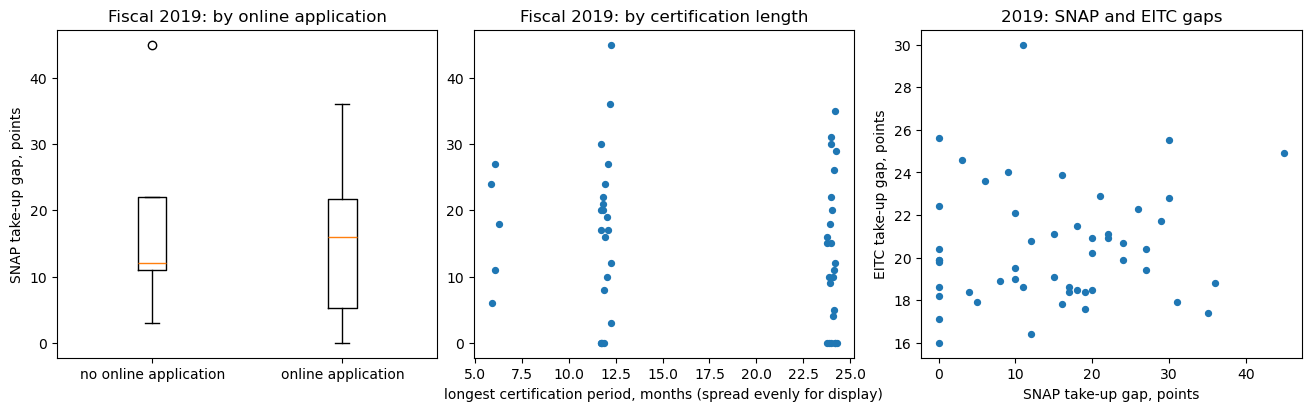

Left: SNAP gap by whether the state offered an online application. Middle: SNAP gap by certification length. Right: SNAP gap against EITC gap. Each point is a state; no point has an interval because none is carried.


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
d = pd.concat([gap[PRIMARY].rename("gap"), feat[USED[PRIMARY]][["online", "months"]]], axis=1)
axes[0].boxplot([d.loc[d["online"] == 0, "gap"], d.loc[d["online"] == 1, "gap"]])
axes[0].set_xticklabels(["no online application", "online application"])
axes[0].set_ylabel("SNAP take-up gap, points"); axes[0].set_title(f"Fiscal {PRIMARY}: by online application")
axes[1].scatter(d["months"] + ((np.arange(len(d)) * 0.618034) % 1.0 - 0.5) * 0.6, d["gap"], s=18)
axes[1].set_xlabel("longest certification period, months (spread evenly for display)"); axes[1].set_title(f"Fiscal {PRIMARY}: by certification length")
e = pd.concat([gap[PRIMARY].rename("snap"), (100 - eitc[f"Tax year {PRIMARY}"]).rename("eitc")], axis=1)
axes[2].scatter(e["snap"], e["eitc"], s=18); axes[2].set_xlabel("SNAP take-up gap, points"); axes[2].set_ylabel("EITC take-up gap, points"); axes[2].set_title(f"{PRIMARY}: SNAP and EITC gaps")
plt.show()
print("Left: SNAP gap by whether the state offered an online application. Middle: SNAP gap by certification length. Right: SNAP gap against EITC gap. Each point is a state; no point has an interval because none is carried.")

## Limitations

- **Association only, across at most fifty-one states.** States that adopt online applications or longer certification periods differ in many ways the notebook does not model; no effect of a feature is estimated, and the text refuses that reading. The unit is the state, so a statement about states says nothing about the households inside them (**ecological inference**), and the arrow can run the other way (**reverse causation**): a state with low take-up may adopt an online application to raise it.
- **Longer certification can raise measured participation without changing who is eligible.** A longer period means fewer recertifications and less churn off the rolls, which raises the participation rate by construction. A positive link between length and take-up is therefore partly a measurement feature, not only a sign of lower burden.
- **Certification length mostly separates the 24-month period for elderly or disabled households from its absence.** Other households are capped at 12 months (the 14th edition states this; the owner's review cites 7 CFR 273.10(f), which was not checked here). The variable is a coarse proxy for administrative burden.
- **The options can be tested in the three fiscal years amendment 3 names, and not in fiscal 2022.** Fiscal 2019 (primary) and fiscal 2018 pair with the 14th edition, fiscal 2016 with the 12th. For fiscal 2022 the 15th edition has no online-application option under any term searched and carries certification periods under a differently worded heading, so the two-feature family cannot be formed; the notebook stops short of recoding that heading, and the owner is asked. The earlier statement that the 15th edition has neither feature was wrong for certification length and is corrected here.
- **The rates are model estimates and are revised.** FNS builds state rates with a shrinkage estimator that averages direct sample estimates with regression predictions; the restated years differ from the original reports (Part 1 prints how much) and Part 4 prints the mean revision beside the contrast tested. A gap difference no larger than a revision cannot be read as a finding.
- **No intervals on the gaps.** The reports publish 90 percent intervals only in a chart whose text is out of reading order, so none is carried; each gap is a point estimate and the bootstrap intervals describe only the sampling of states, not the error in each state's rate. The later reports cap rates at 100, so a state at the cap has a gap of zero that may understate its true gap; the cap already binds for some states in the earliest year used (Part 1 prints the counts).
- **The 14th edition disagrees with itself for a few states.** Its profile pages and its own summary lists give different values for some states (Part 2 names them). The profile page is what is coded, because the plan and amendment 1 name it; Part 4 repeats the tests with those states recoded or left out.
- **Small groups.** The online-application contrast rests on a handful of states without the feature, so the percentile bootstrap interval may be unreliable and the test could detect only a large difference (Part 4 prints both).
- **Timing.** A fiscal year runs October to September and an options report is dated 1 October of a year; the pairing is exact in the replication years and twelve months apart in the primary year (printed in Part 2). The EITC is a tax-year estimate for a different benefit, matched by calendar year, and overlaps without coinciding.
- **Two features, coded by rule.** Certification length is the longest period a state uses; a state with a shorter period too is coded by its longest. "Recertify" only is coded as no online application. Neither is a complete measure of administrative burden.
- **PDF text extraction is a parse, not proof.** It is tested on constructed text and on the real extracted text of the tables and profile pages, and checked by a coverage rule, a range check, a second read of the same text (a consistency check), the agreement of restated years and the options report's own summary lists. Three repairs (a name split across lines, a number split in two, and exclusion of an unreadable row) are printed when they occur. A table that read cleanly may still hold an error these checks cannot see.
- **Unweighted.** The gap is not weighted by population; the unit is the state. The jurisdiction list comes from the repository's policy table, not the FIPS table the plan names.
- **Departures from the plan.** The plan was not edited. Amendment 1 narrowed the years in which the options are tested, allowed the three repairs, and fixed how the features are coded, after the files had been read for layout (including the fiscal 2019 table's parse) and before any gap or association was computed. Amendment 2 assigned a headingless profile page by page number. Amendment 3, an owner ruling, made fiscal 2019 the primary year because amendment 1 had misapplied plan section 4. Whether the layout reading influenced the choice of years is for the reader to weigh; the first printed gap or association is in this notebook's stored run, after amendment 3.
- **Added after review (not pre-specified, 2026-10-29):** the restatement comparison for all restated years, the comparison with the options report's own summary lists, the detectable-difference and small-group lines, the revision-size comparison, the broader term search and contents headings for the 15th and 17th editions, and the sign-only lines. None changes a plan estimand or estimator.
- **Provenance.** The ledger lines for the layout reads and for the first two completed runs are reconstructed from saved bytes and file times, with timestamps estimated where marked; the plan chain on the 28 October 11:33Z lines was back-filled. Each says so in its `note`.

## Key Takeaways

1. A take-up gap is the share of eligible people who do not receive a benefit; it depends entirely on how "eligible" was estimated, so it carries that estimate's error even when no interval is printed.
2. Tables that exist only in a PDF can be read by a parser, but a parse is a claim to be checked: coverage, range, a second read, the agreement of years that two reports both print, and the report's own summary. Test the parser on the real text it will meet, not only on text you constructed.
3. An association across states between an administrative feature and take-up is a description. The design that would support an effect needs variation in timing within states and a test of pre-trends.
4. When the data that would test a hypothesis are missing for the year you care about, say so and test where you can, rather than substituting something near. Search with more than one term before saying a thing is absent.
5. Report a null with its interval and say what size of difference the data could have detected; a state-level association based on a few dozen states is often not distinguishable from zero at the precision available.

## Exercises

1. Code certification length as the shortest period a state uses instead of the longest and repeat the association for the primary year. Does the sign change?
2. Add the number of options a state has adopted from the same profile page as a third feature. How many tests are in the family now, and what does Holm do to the earlier two?
3. Compare the SNAP gap in fiscal 2019 and fiscal 2022 state by state. Which states moved most, and could the options report explain any of it?
4. Describe the event-study design that would estimate the effect of an online application on take-up. What data would you need that this notebook does not have?
5. Recode certification length in the 15th edition from its differently worded heading and test fiscal 2022 on that one feature. What would you have to decide before doing it, and who should decide it?

## References

Author, year and venue as recalled; **not verified against the published record in this build**.

- Cunnyngham, K., *Reaching Those in Need: Estimates of State Supplemental Nutrition Assistance Program Participation Rates*, USDA Food and Nutrition Service (the report for each year used here, which describes the shrinkage estimator).
- USDA Food and Nutrition Service, *SNAP State Options Report* (12th, 14th, 15th and 17th editions).
- Internal Revenue Service, *EITC participation rate by state*.
- Herd, P. and Moynihan, D. (2018), *Administrative Burden: Policymaking by Other Means*, Russell Sage Foundation.
- Callaway, B. and Sant'Anna, P. (2021), *Difference-in-Differences with Multiple Time Periods*, Journal of Econometrics (the staggered-adoption design treated in notebook C03).